# Predicción de cancelación de clientes en Netflix
### Comparación de clasificadores de aprendizaje supervisado

**Integrantes:** Ricardo Villarreal · Juan Carlos Flores

**Dataset:** [Netflix Customer Churn and Engagement Analytics (Kaggle)](https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics/data) — 5,000 clientes, 14 columnas.

**Pregunta de negocio:** ¿podemos anticipar qué clientes van a cancelar su suscripción, para que el equipo de retención actúe *antes* de perderlos? ¿Qué algoritmo lo hace mejor?

---

In [32]:
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

df = pd.read_csv('netflix_customer_churn.csv')

df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [33]:
display(df.info())
display(df.columns)
display(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

None

Index(['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours',
       'last_login_days', 'region', 'device', 'monthly_fee', 'churned',
       'payment_method', 'number_of_profiles', 'avg_watch_time_per_day',
       'favorite_genre'],
      dtype='str')

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

In [34]:
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

porcentaje_nulos

#No existen valores nulos en el dataset, por lo que no es necesario realizar ninguna limpieza de datos.

customer_id               0.0
age                       0.0
gender                    0.0
subscription_type         0.0
watch_hours               0.0
last_login_days           0.0
region                    0.0
device                    0.0
monthly_fee               0.0
churned                   0.0
payment_method            0.0
number_of_profiles        0.0
avg_watch_time_per_day    0.0
favorite_genre            0.0
dtype: float64

In [35]:
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


In [36]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


In [37]:
print(df["age"].median())
print(df["watch_hours"].median())
print(df["monthly_fee"].median())
print(df["last_login_days"].median())
print(df["number_of_profiles"].median())

44.0
8.0
13.99
30.0
3.0


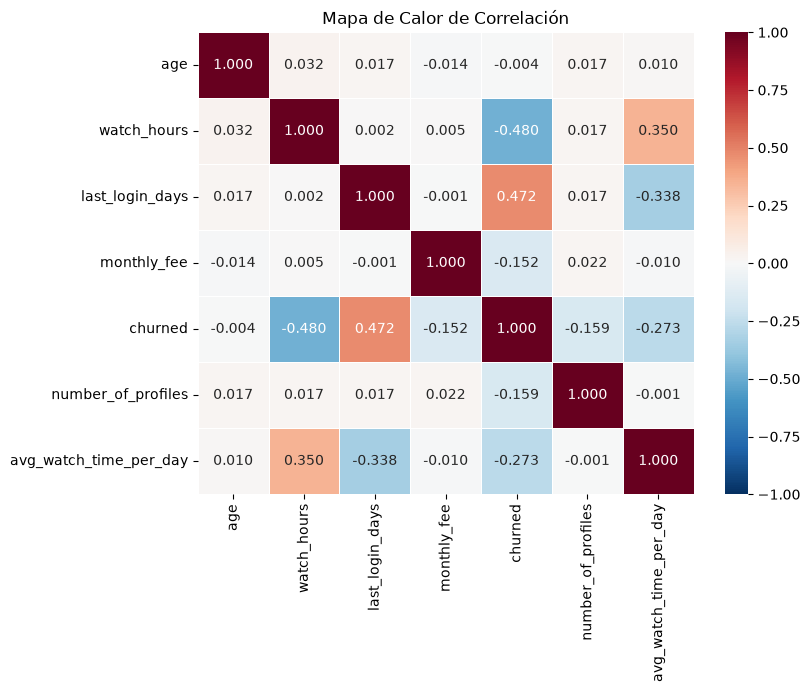

In [38]:
matriz_corr = df.select_dtypes(include=['float64', 'int64']).corr()
# O simplemente: matriz_corr = df.corr(numeric_only=True)

# 3. Configurar el tamaño de la figura
plt.figure(figsize=(8, 6))

# 4. Generar el mapa de calor
sns.heatmap(
    matriz_corr,
    annot=True,  # Muestra los valores numéricos en cada celda
    fmt='.3f',  # Formato de dos decimales
    cmap='RdBu_r',  # Paleta de colores
    linewidths=0.5,  # Líneas divisorias entre celdas
    vmin=-1,
    vmax=1,
)

# 5. Mostrar el gráfico
plt.title('Mapa de Calor de Correlación')
plt.show()

In [39]:
variables = [
    "age",
    "subscription_type",
    "watch_hours",
    "last_login_days",
    "device",
    "payment_method",
    "number_of_profiles",
    "avg_watch_time_per_day",
    "monthly_fee"
]



In [40]:
target = "churned"
df_modelo = df[variables + [target]].copy()

df_modelo.head()

,age,subscription_type,watch_hours,last_login_days,device,payment_method,number_of_profiles,avg_watch_time_per_day,monthly_fee,churned
0,51,Basic,14.73,29,TV,Gift Card,1,0.49,8.99,1
1,47,Standard,0.70,19,Mobile,Gift Card,5,0.03,13.99,1
2,27,Standard,16.32,10,TV,Crypto,2,1.48,13.99,0
3,53,Premium,4.51,12,TV,Crypto,2,0.35,17.99,1
4,56,Standard,1.89,13,Mobile,Crypto,2,0.13,13.99,1


In [41]:
variables_numericas = [
    "age",
    "watch_hours",
    "last_login_days",
    "number_of_profiles",
    "avg_watch_time_per_day",
    "monthly_fee"
]

variables_categoricas = [
    "subscription_type",
    "device",
    "payment_method"
]

for columna in variables_categoricas:
    print("\n", columna)
    print(df_modelo[columna].value_counts())


 subscription_type
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

 device
device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

 payment_method
payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64


In [42]:
df_encoded = pd.get_dummies(
    df_modelo,
    columns=variables_categoricas,
    dtype=int
)

df_encoded.head()

,age,watch_hours,last_login_days,number_of_profiles,avg_watch_time_per_day,monthly_fee,churned,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard,device_Desktop,device_Laptop,device_Mobile,device_TV,device_Tablet,payment_method_Credit Card,payment_method_Crypto,payment_method_Debit Card,payment_method_Gift Card,payment_method_PayPal
0,51,14.73,29,1,0.49,8.99,1,1,0,0,0,0,0,1,0,0,0,0,1,0
1,47,0.70,19,5,0.03,13.99,1,0,0,1,0,0,1,0,0,0,0,0,1,0
2,27,16.32,10,2,1.48,13.99,0,0,0,1,0,0,0,1,0,0,1,0,0,0
3,53,4.51,12,2,0.35,17.99,1,0,1,0,0,0,0,1,0,0,1,0,0,0
4,56,1.89,13,2,0.13,13.99,1,0,0,1,0,0,1,0,0,0,1,0,0,0


In [43]:
df_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         5000 non-null   int64  
 1   watch_hours                 5000 non-null   float64
 2   last_login_days             5000 non-null   int64  
 3   number_of_profiles          5000 non-null   int64  
 4   avg_watch_time_per_day      5000 non-null   float64
 5   monthly_fee                 5000 non-null   float64
 6   churned                     5000 non-null   int64  
 7   subscription_type_Basic     5000 non-null   int64  
 8   subscription_type_Premium   5000 non-null   int64  
 9   subscription_type_Standard  5000 non-null   int64  
 10  device_Desktop              5000 non-null   int64  
 11  device_Laptop               5000 non-null   int64  
 12  device_Mobile               5000 non-null   int64  
 13  device_TV                   5000 non-null   

In [44]:
df_encoded.shape

(5000, 20)

In [45]:
df_encoded.describe()

,age,watch_hours,last_login_days,number_of_profiles,avg_watch_time_per_day,monthly_fee,churned,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard,device_Desktop,device_Laptop,device_Mobile,device_TV,device_Tablet,payment_method_Credit Card,payment_method_Crypto,payment_method_Debit Card,payment_method_Gift Card,payment_method_PayPal
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,3.024400,0.874800,13.683400,0.503000,0.332200,0.338600,0.32920,0.189800,0.201200,0.200800,0.198600,0.209600,0.194600,0.199000,0.206000,0.195200,0.205200
std,15.501128,12.014654,17.536078,1.415841,2.619824,3.692062,0.500041,0.471049,0.473281,0.46997,0.392182,0.400937,0.400639,0.398986,0.407064,0.395932,0.399288,0.404471,0.396394,0.403888
min,18.000000,0.010000,0.000000,1.000000,0.000000,8.990000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,3.337500,15.000000,2.000000,0.110000,8.990000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,44.000000,8.000000,30.000000,3.000000,0.290000,13.990000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,58.000000,16.030000,45.000000,4.000000,0.720000,17.990000,1.000000,1.000000,1.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,70.000000,110.400000,60.000000,5.000000,98.420000,17.990000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


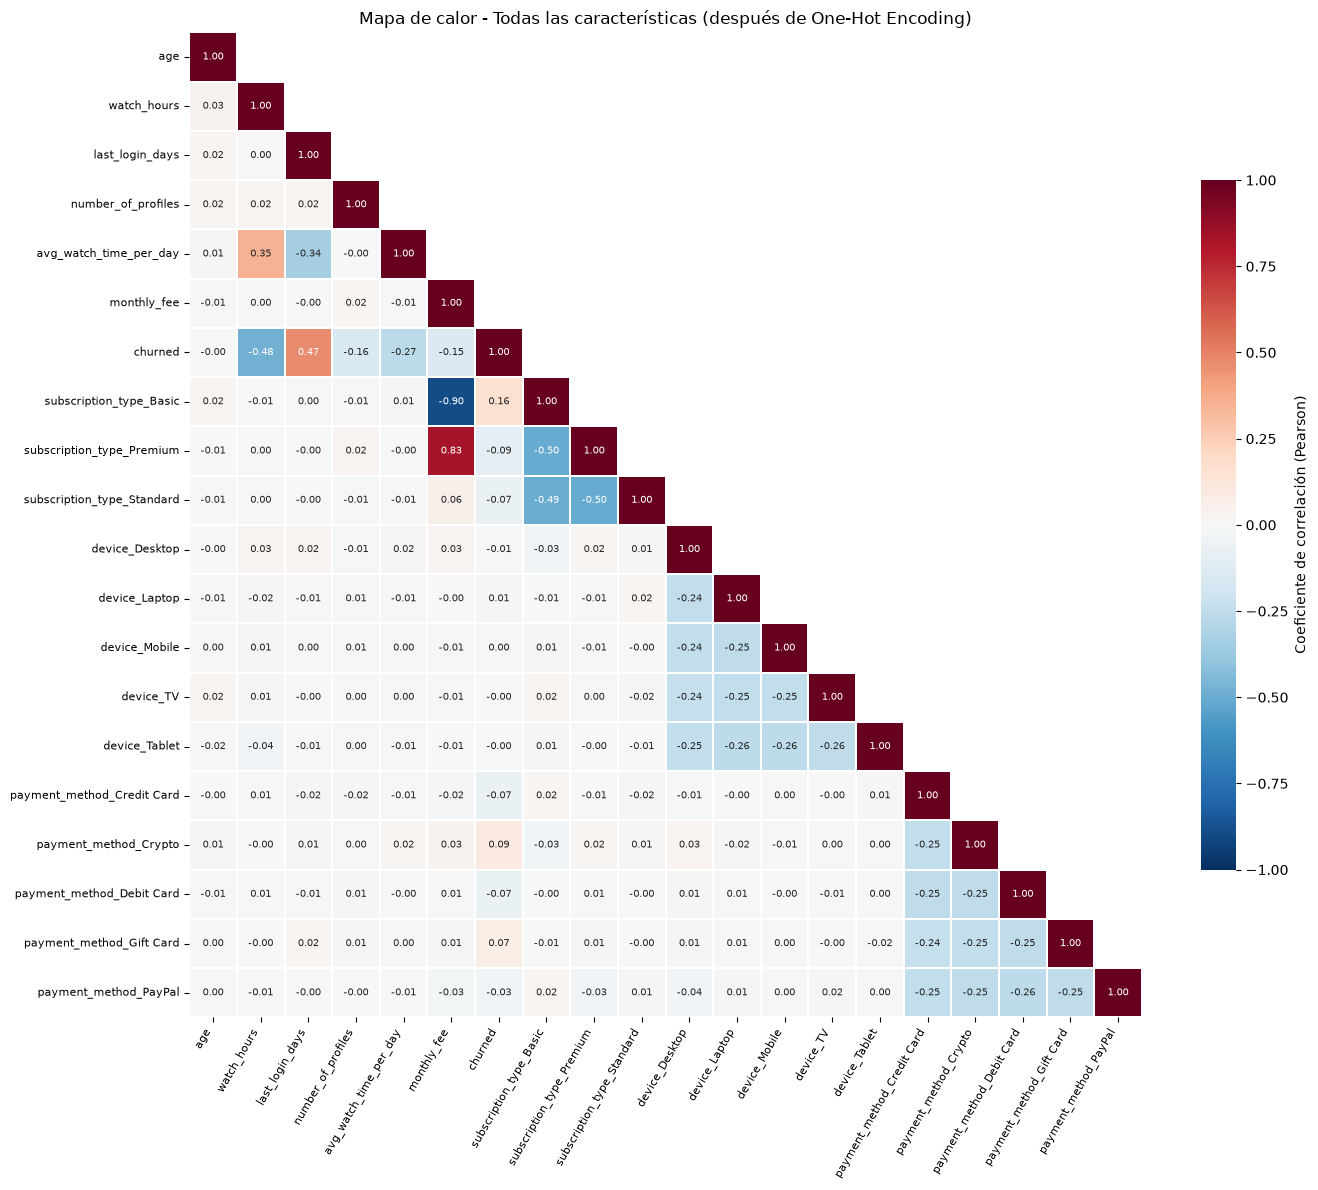

In [46]:
# Correlación de todas las columnas del dataset codificado
corr_total = df_encoded.corr()
mascara_total = np.triu(np.ones_like(corr_total, dtype=bool), k=1)

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_total,
    mask=mascara_total,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cmap="RdBu_r",
    vmin=-1, vmax=1, center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.7, "label": "Coeficiente de correlación (Pearson)"}
)
plt.title("Mapa de calor - Todas las características (después de One-Hot Encoding)")
plt.xticks(rotation=60, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [47]:
X = df_encoded.drop(columns=["churned"])
y = df_encoded["churned"]

display(X.head())
display(y.head())

,age,watch_hours,last_login_days,number_of_profiles,avg_watch_time_per_day,monthly_fee,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard,device_Desktop,device_Laptop,device_Mobile,device_TV,device_Tablet,payment_method_Credit Card,payment_method_Crypto,payment_method_Debit Card,payment_method_Gift Card,payment_method_PayPal
0,51,14.73,29,1,0.49,8.99,1,0,0,0,0,0,1,0,0,0,0,1,0
1,47,0.70,19,5,0.03,13.99,0,0,1,0,0,1,0,0,0,0,0,1,0
2,27,16.32,10,2,1.48,13.99,0,0,1,0,0,0,1,0,0,1,0,0,0
3,53,4.51,12,2,0.35,17.99,0,1,0,0,0,0,1,0,0,1,0,0,0
4,56,1.89,13,2,0.13,13.99,0,0,1,0,0,1,0,0,0,1,0,0,0


0    1
1    1
2    0
3    1
4    1
Name: churned, dtype: int64

In [48]:
y.value_counts()

churned
1    2515
0    2485
Name: count, dtype: int64

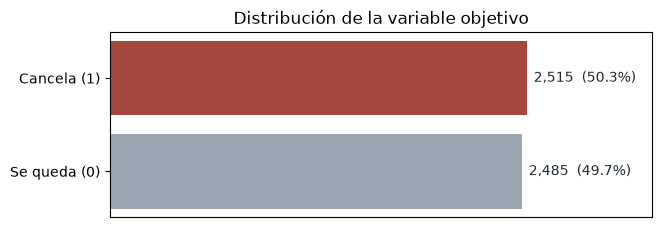

In [49]:
C_CANCELA, C_QUEDA, ACCENT = "#A4483F", "#9AA5B1", "#C8963E"
INK, MUTED, GRID = "#1F2A37", "#6B7280", "#ECE9E2"

fig, ax = plt.subplots(figsize=(7, 2.4))
counts = y.value_counts().reindex([0, 1], fill_value=0)
labels = ["Se queda (0)", "Cancela (1)"]
y_pos = range(len(labels))

ax.barh(y_pos, counts.values, color=[C_QUEDA, C_CANCELA], height=0.8)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(labels)

for i, v in enumerate(counts.values):
    ax.text(v + 40, i, f"{v:,}  ({v/len(y):.1%})", va="center", color=INK)

ax.set_xlim(0, counts.max() * 1.3)
ax.set_xticks([])
ax.grid(False)
ax.set_title("Distribución de la variable objetivo")
plt.show()

for i, v in enumerate(counts.values):
    ax.text(
        v + 40,
        i,
        f"{v:,} ({v/len(y):.1%})",
        va="center",
        color=INK
    )

Para iniciar el proceso se importaron las librerías necesarias para la creación del modelo de clasificación, así como la división de los datos en conjuntos de entrenamiento y prueba.

Se seleccionaron ocho variables originales para el entrenamiento de los clasificadores. Se aplicó One-Hot Encoding a las tres variables categóricas, obteniendo un total de 18 características predictoras numéricas y una variable objetivo (churned), para un total de 19 columnas.

Login_days nos dice cuantos días han pasado desde la última vez que el usuario inició sesión en Netflix. Los usuarios que han iniciado sesión recientemente son menos propensos a abandonar el servicio, mientras que aquellos que no han iniciado sesión durante un período prolongado pueden estar en riesgo de churn. Por lo tanto, esta variable puede ser un buen predictor de churn.

## Hipótesis

El objetivo de este proyecto es analizar el comportamiento de los usuarios de Netflix para identificar patrones asociados con el abandono de la plataforma.

La variable objetivo será **`churned`**, la cual indica si un usuario dejó o canceló el servicio:

- **0:** El usuario permanece en la plataforma.
- **1:** El usuario abandonó o canceló el servicio.

A partir de variables relacionadas con el comportamiento y características de los usuarios, se utilizarán diferentes modelos de clasificación para estimar la probabilidad de que un cliente abandone la plataforma.

Se compararán los modelos **Naive Bayes, K-Nearest Neighbors (KNN), Decision Tree y Neural Network**, utilizando métricas de evaluación como **Accuracy, Precision, Recall, F1-Score y ROC-AUC**, con el objetivo de determinar cuál clasificador presenta el mejor desempeño para predecir el abandono de usuarios.

In [50]:
# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División y preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Clasificadores
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    auc
)


In [51]:
# Separamos los datos en entrenamiento (80%) y prueba (20%)
# El modelo aprende con X_train y se evalúa con X_test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Revisamos cuántos datos quedaron en cada grupo
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (4000, 19)
Datos de prueba: (1000, 19)


In [52]:
# Creamos el modelo Naive Bayes
# Este modelo utiliza probabilidades para determinar
# a qué clase pertenece cada usuario

modelo_nb = GaussianNB()

# Entrenamos el modelo con los datos de entrenamiento
modelo_nb.fit(X_train, y_train)

# Realizamos predicciones con usuarios que el modelo no vio durante el entrenamiento
y_pred_nb = modelo_nb.predict(X_test)

In [53]:
# Calculamos el Accuracy del modelo
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Accuracy Naive Bayes:", accuracy_nb)

Accuracy Naive Bayes: 0.819


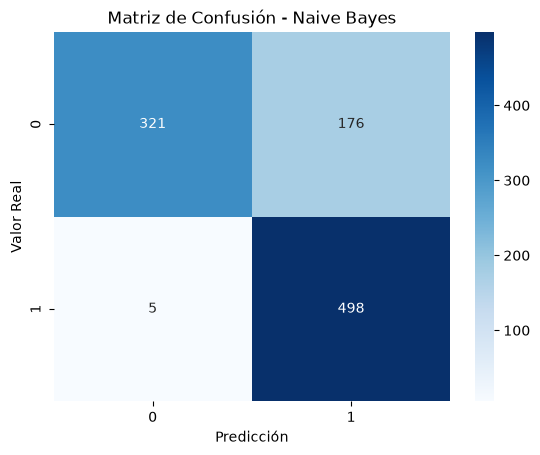

In [54]:
# Creamos la matriz de confusión para observar
# cuántos usuarios fueron clasificados correctamente e incorrectamente

matriz_nb = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(
    matriz_nb,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matriz de Confusión - Naive Bayes")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

In [55]:
# Creamos el escalador
# StandardScaler coloca las variables numéricas en escalas comparables

scaler = StandardScaler()

# Aprendemos la escala solamente utilizando los datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Aplicamos la misma transformación a los datos de prueba
X_test_scaled = scaler.transform(X_test)

In [56]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline

# Probamos  valores de k utilizando validación cruzada
valores_k = [1, 2, 3, 4, 5, 7, 9, 11]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Creamos un Pipeline para escalar dentro de cada partición
pipeline_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

# Buscamos el mejor k utilizando F1-Score
busqueda_knn = GridSearchCV(
    pipeline_knn,
    param_grid={
        "kneighborsclassifier__n_neighbors": valores_k
    },
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# Solamente utilizamos los datos de entrenamiento
busqueda_knn.fit(X_train, y_train)

# Guardamos el mejor modelo
modelo_knn_best = busqueda_knn.best_estimator_
mejor_k = busqueda_knn.best_params_[
    "kneighborsclassifier__n_neighbors"
]

print("Mejor k:", mejor_k)
print("F1 promedio CV:", busqueda_knn.best_score_)

# Comparamos los cuatro valores utilizando F1 de validación
df_resultados_knn = pd.DataFrame({
    "k": valores_k,
    "F1_CV": busqueda_knn.cv_results_["mean_test_score"]
})

display(df_resultados_knn)

/opt/anaconda3/envs/DATAanalisis/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/DATAanalisis/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/DATAanalisis/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/DATAanalisis/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (v

Mejor k: 3
F1 promedio CV: 0.8307142129980987


,k,F1_CV
0,1,0.830312
1,2,0.793060
2,3,0.830714
3,4,0.810791
4,5,0.818227
5,7,0.812243
6,9,0.807809
7,11,0.806852


Mejor KNN: k=3
Accuracy: 0.8290
              precision    recall  f1-score   support

           0       0.85      0.79      0.82       497
           1       0.81      0.86      0.84       503

    accuracy                           0.83      1000
   macro avg       0.83      0.83      0.83      1000
weighted avg       0.83      0.83      0.83      1000



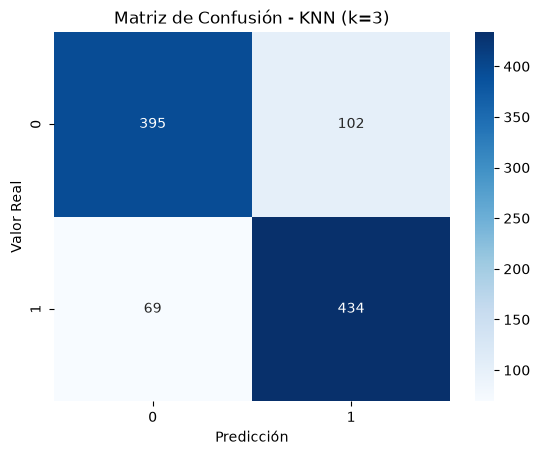

In [57]:
# Evaluamos el mejor KNN sobre los datos de prueba

y_pred_knn = modelo_knn_best.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Mejor KNN: k={mejor_k}")
print(f"Accuracy: {accuracy_knn:.4f}")
print(classification_report(y_test, y_pred_knn))

# Matriz de confusión
matriz_knn = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(
    matriz_knn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(f"Matriz de Confusión - KNN (k={mejor_k})")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

In [58]:
# Creamos el modelo de Árbol de Decisión
# El modelo aprende reglas de decisión para separar
# a los usuarios que abandonan de los que permanecen

modelo_dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Entrenamos el modelo con los datos de entrenamiento
modelo_dt.fit(X_train, y_train)

# Realizamos predicciones con los datos de prueba
y_pred_dt = modelo_dt.predict(X_test)

In [59]:
# Calculamos el Accuracy del Árbol de Decisión
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Accuracy Decision Tree:", accuracy_dt)

Accuracy Decision Tree: 0.926


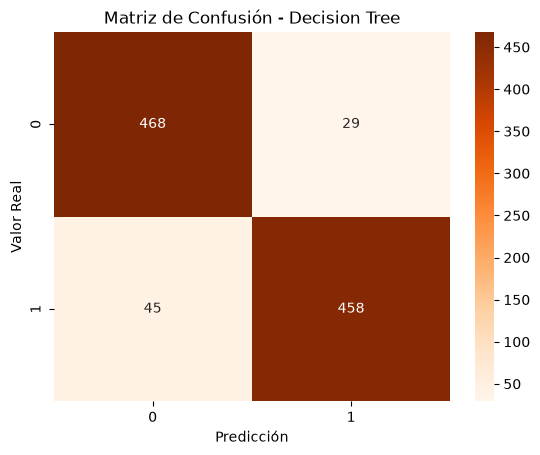

In [60]:
# Creamos la matriz de confusión
# para analizar aciertos y errores del modelo

matriz_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(
    matriz_dt,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Matriz de Confusión - Decision Tree")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

In [61]:
# Creamos el modelo Random Forest
# Utiliza varios árboles y combina sus decisiones para realizar la clasificación

modelo_rf = RandomForestClassifier(
    n_estimators=100,   # Número de árboles
    max_depth=5,        # Profundidad máxima de cada árbol
    random_state=42
)

# Entrenamos el modelo con los datos originales
modelo_rf.fit(X_train, y_train)

# Realizamos las predicciones
y_pred_rf = modelo_rf.predict(X_test)

# Calculamos las probabilidades de pertenecer a churned = 1
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Evaluamos el modelo
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Accuracy Random Forest:", accuracy_rf)
print(classification_report(y_test, y_pred_rf))

Accuracy Random Forest: 0.951
              precision    recall  f1-score   support

           0       0.98      0.92      0.95       497
           1       0.93      0.98      0.95       503

    accuracy                           0.95      1000
   macro avg       0.95      0.95      0.95      1000
weighted avg       0.95      0.95      0.95      1000



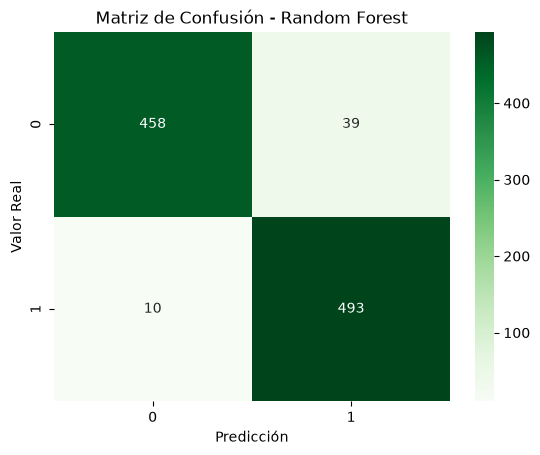

In [62]:
# Matriz de confusión de Random Forest

matriz_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    matriz_rf,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

In [63]:
# Creamos una red neuronal MLP
# La red intenta aprender relaciones más complejas entre las variables

modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),  # Dos capas ocultas
    activation="relu",
    max_iter=1000,
    random_state=42
)

# Entrenamos utilizando los datos escalados
modelo_mlp.fit(X_train_scaled, y_train)

# Realizamos predicciones
y_pred_mlp = modelo_mlp.predict(X_test_scaled)

# Obtenemos probabilidades para churned = 1
y_prob_mlp = modelo_mlp.predict_proba(X_test_scaled)[:, 1]

# Evaluamos
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

print("Accuracy MLP:", accuracy_mlp)
print(classification_report(y_test, y_pred_mlp))

Accuracy MLP: 0.919
              precision    recall  f1-score   support

           0       0.93      0.90      0.92       497
           1       0.91      0.93      0.92       503

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000



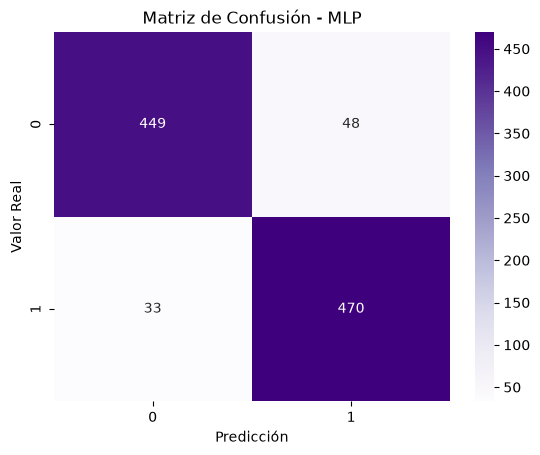

In [64]:
# Matriz de confusión de la red neuronal

matriz_mlp = confusion_matrix(y_test, y_pred_mlp)

sns.heatmap(
    matriz_mlp,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("Matriz de Confusión - MLP")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

In [65]:
# Creamos el clasificador SVM
# Busca una frontera óptima para separar churned = 0 y churned = 1
# Clasificador SVM con kernel RBF
# Utilizamos decision_function para las curvas ROC y PR

from sklearn.svm import SVC

modelo_svm = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

# Entrenamos utilizando datos escalados
modelo_svm.fit(X_train_scaled, y_train)

# Predicciones de clase
y_pred_svm = modelo_svm.predict(X_test_scaled)

# Puntuaciones de decisión, no probabilidades
y_score_svm = modelo_svm.decision_function(X_test_scaled)

# Evaluación
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Accuracy SVM:", accuracy_svm)
print(classification_report(y_test, y_pred_svm))

Accuracy SVM: 0.914
              precision    recall  f1-score   support

           0       0.92      0.91      0.91       497
           1       0.91      0.92      0.92       503

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



In [66]:
from sklearn.metrics import average_precision_score

# Reunimos todos los modelos ya entrenados
# Indicamos qué datos necesita cada clasificador

modelos_evaluados = {
    "Naive Bayes": (modelo_nb, X_test),
    f"KNN (k={mejor_k})": (modelo_knn_best, X_test),
    "Decision Tree": (modelo_dt, X_test),
    "Random Forest": (modelo_rf, X_test),
    "MLP": (modelo_mlp, X_test_scaled),
    "SVM": (modelo_svm, X_test_scaled)
}

# Guardamos métricas, predicciones y puntuaciones
filas = []
predicciones = {}
puntajes_roc_pr = {}
matrices_confusion = {}

for nombre, (modelo, datos_test) in modelos_evaluados.items():

    # Predicciones de clase
    y_pred = modelo.predict(datos_test)

    # Probabilidades o puntuaciones de decisión
    if hasattr(modelo, "predict_proba"):
        scores = modelo.predict_proba(datos_test)[:, 1]
    else:
        scores = modelo.decision_function(datos_test)

    # Guardamos para las visualizaciones
    predicciones[nombre] = y_pred
    puntajes_roc_pr[nombre] = scores
    matrices_confusion[nombre] = confusion_matrix(
        y_test, y_pred
    )

    # Calculamos las métricas para churned = 1
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Average Precision": average_precision_score(
            y_test, scores
        )
    })

# Creamos una tabla completa
resultados = pd.DataFrame(filas)

# Ordenamos de mayor a menor F1
resultados = resultados.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(resultados.round(4))


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Random Forest,0.951,0.9267,0.9801,0.9527,0.9947,0.9955
1,Decision Tree,0.926,0.9405,0.9105,0.9253,0.9775,0.9730
2,MLP,0.919,0.9073,0.9344,0.9207,0.9814,0.9821
3,SVM,0.914,0.9080,0.9225,0.9152,0.9732,0.9744
4,Naive Bayes,0.819,0.7389,0.9901,0.8462,0.9492,0.9488
5,KNN (k=3),0.829,0.8097,0.8628,0.8354,0.8885,0.8457


In [67]:
# Obtenemos probabilidades de los modelos anteriores

y_prob_nb = modelo_nb.predict_proba(X_test)[:, 1]

y_prob_dt = modelo_dt.predict_proba(X_test)[:, 1]

In [68]:
mejor_k = busqueda_knn.best_params_["kneighborsclassifier__n_neighbors"]
modelo_knn_best = KNeighborsClassifier(n_neighbors=mejor_k)

modelo_knn_best.fit(X_train_scaled, y_train)

y_prob_knn = modelo_knn_best.predict_proba(X_test_scaled)[:, 1]

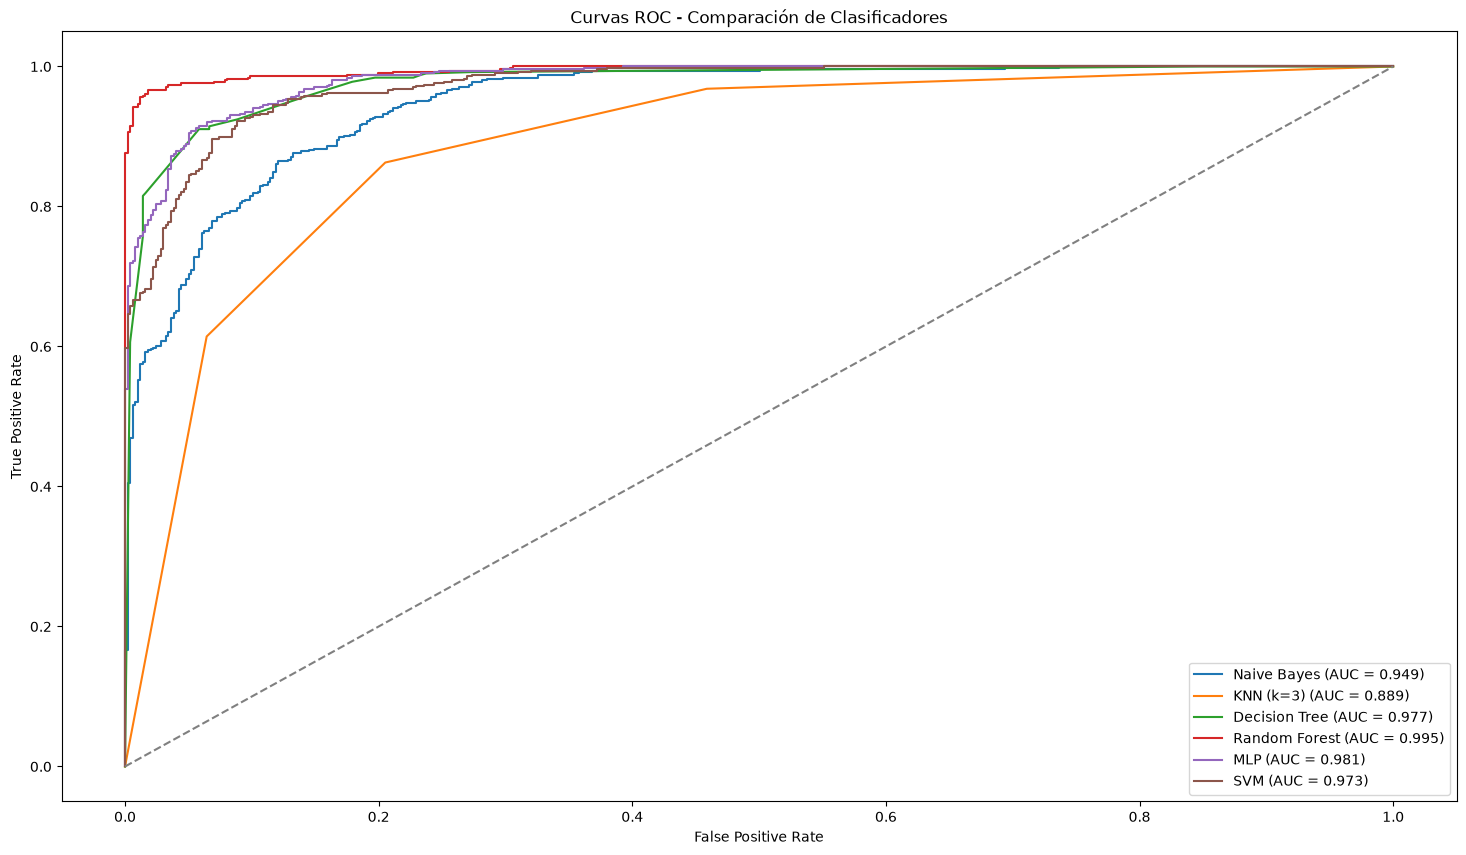

In [69]:
# Comparamos la capacidad de todos los clasificadores
# para distinguir Churn de No Churn

plt.figure(figsize=(18, 10))

for nombre, scores in puntajes_roc_pr.items():

    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc = roc_auc_score(y_test, scores)

    plt.plot(
        fpr, tpr,
        label=f"{nombre} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curvas ROC - Comparación de Clasificadores")
plt.legend()
plt.show()

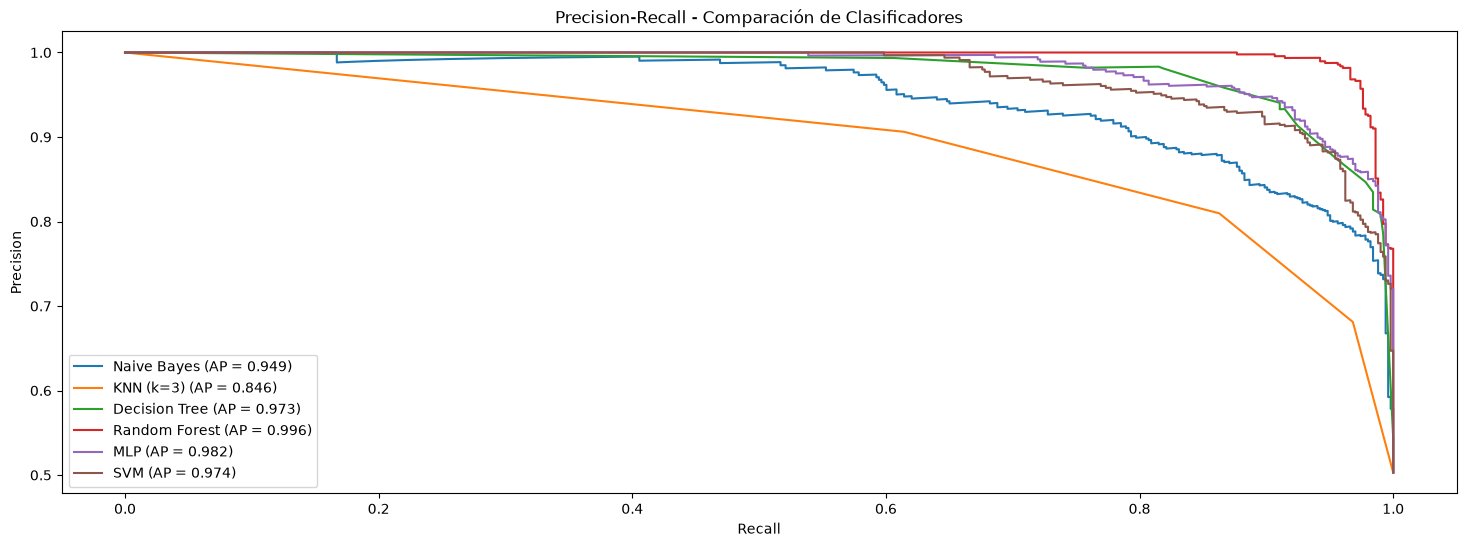

In [70]:
# Comparamos Precision y Recall de los seis modelos

from sklearn.metrics import precision_recall_curve


plt.figure(figsize=(18, 6))

for nombre, scores in puntajes_roc_pr.items():

    precision, recall, _ = precision_recall_curve(
        y_test, scores
    )

    ap = average_precision_score(y_test, scores)

    plt.plot(
        recall, precision,
        label=f"{nombre} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall - Comparación de Clasificadores")
plt.legend()
plt.show()

In [71]:
from sklearn import tree
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from mlxtend.plotting import plot_decision_regions

In [72]:
from sklearn.model_selection import cross_val_score

# Evaluamos la estabilidad de Random Forest
# con cinco particiones del entrenamiento

scores_rf = cross_val_score(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("F1 por partición:", scores_rf)
print("F1 promedio:", scores_rf.mean())
print("Desviación estándar:", scores_rf.std())

F1 por partición: [0.95460123 0.92551893 0.94117647 0.94939759 0.95736906]
F1 promedio: 0.9456126551163677
Desviación estándar: 0.011460985709172644


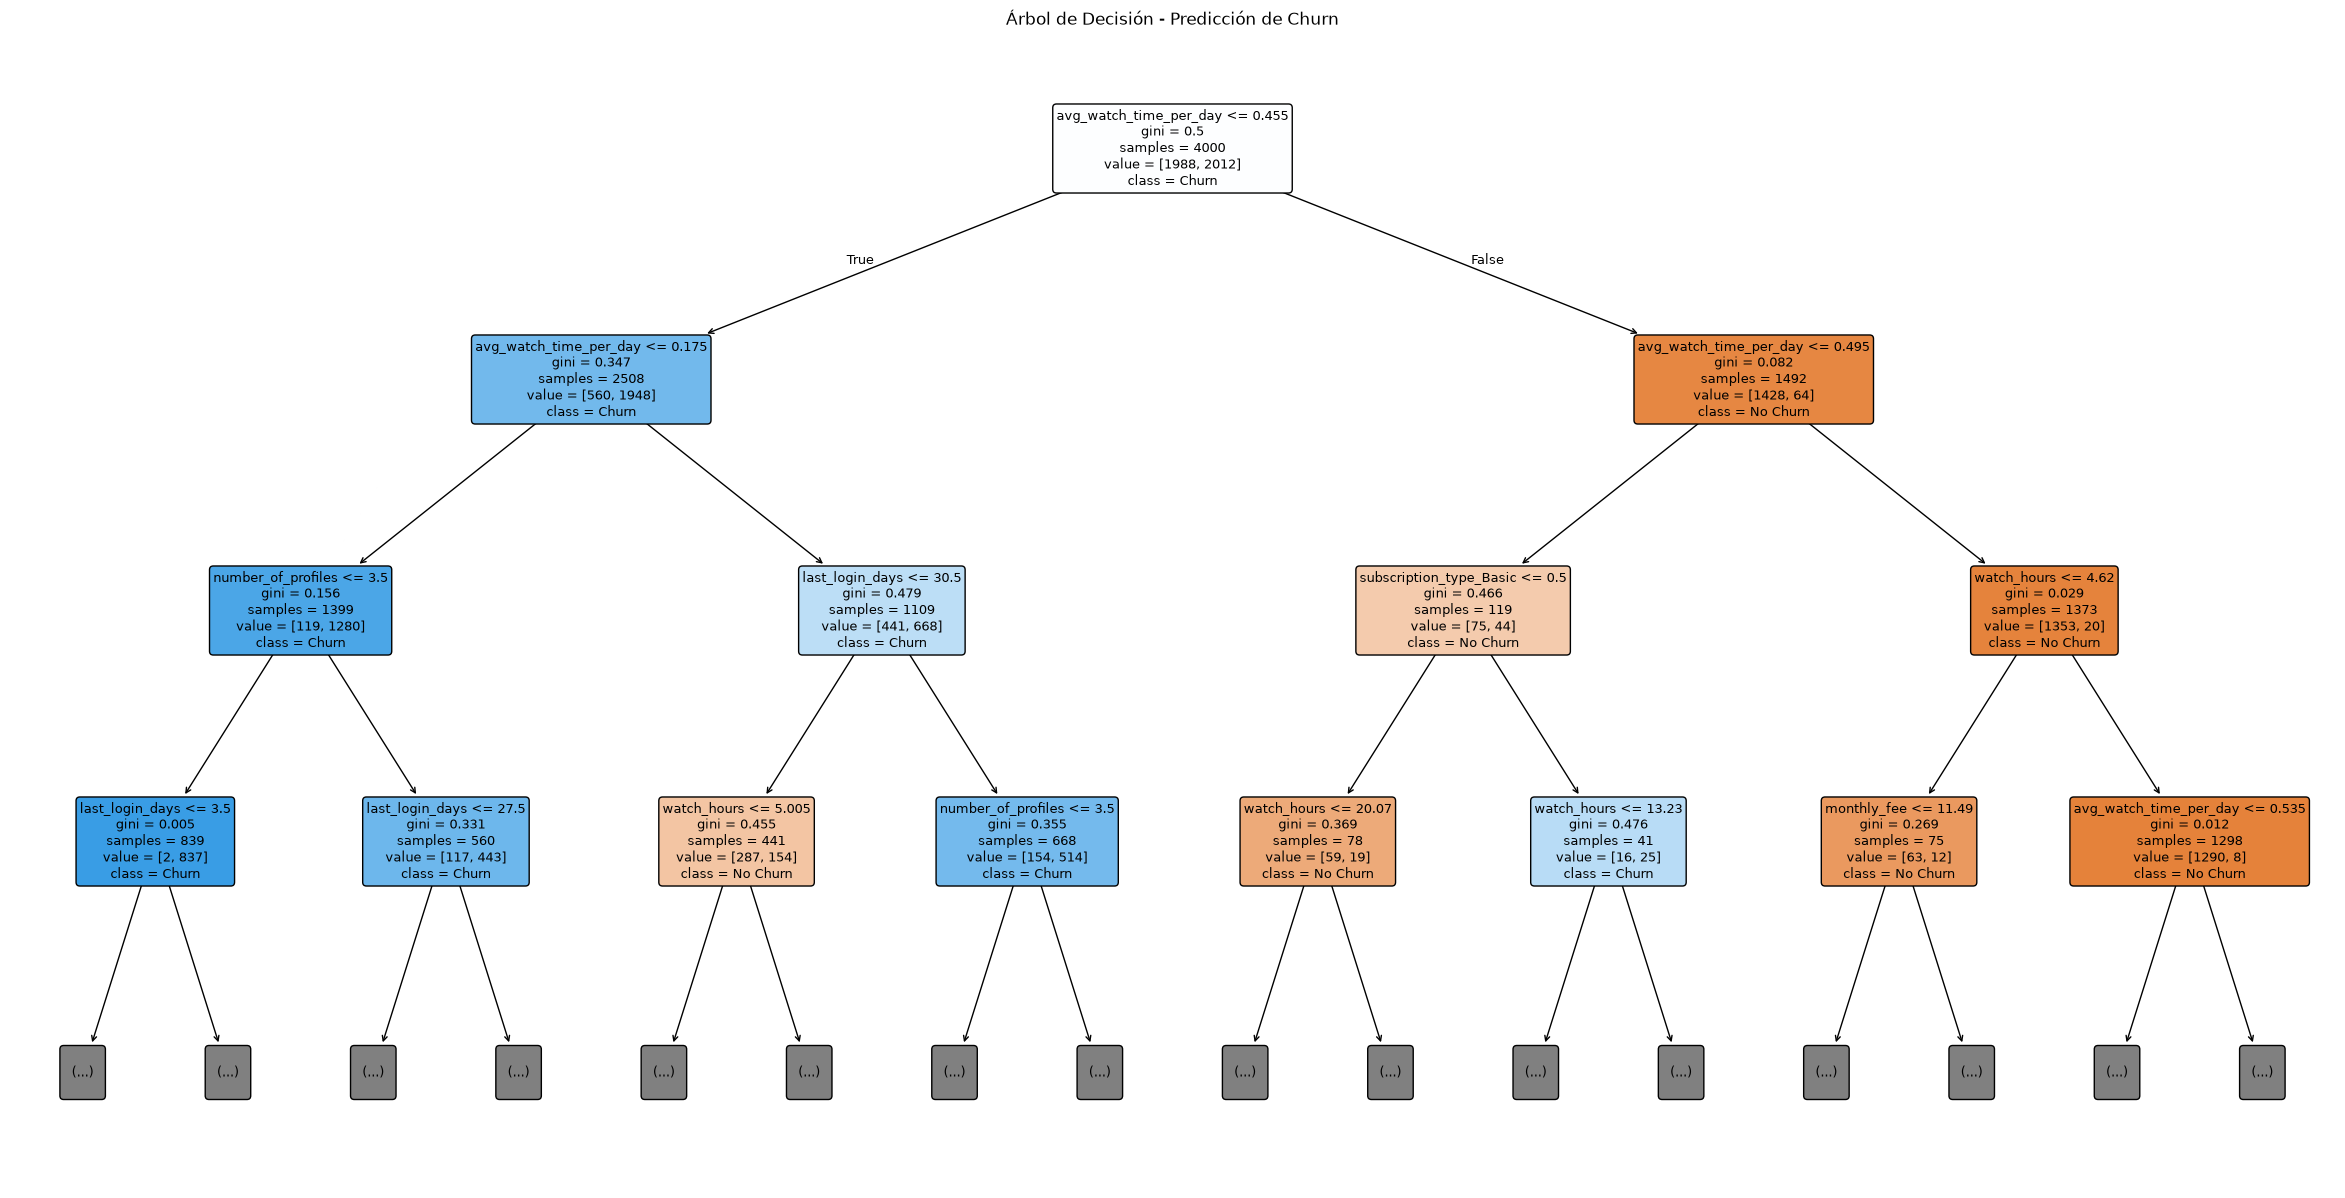

In [73]:
# Mostramos gráficamente las reglas aprendidas por el Decision Tree
# Cada nodo representa una pregunta sobre alguna característica del usuario

plt.figure(figsize=(30, 15))

tree.plot_tree(
    modelo_dt,
    feature_names=X.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Árbol de Decisión - Predicción de Churn")
plt.show()

In [74]:
# Modelos utilizados únicamente para visualizar las regiones de decisión
# Los modelos que necesitan escalamiento utilizan un Pipeline

modelos_2d = {
    
    "Naive Bayes": GaussianNB(),

    f"KNN (k={mejor_k})": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=mejor_k)
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ),

    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=1000,
            random_state=42
        )
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        )
    )
}

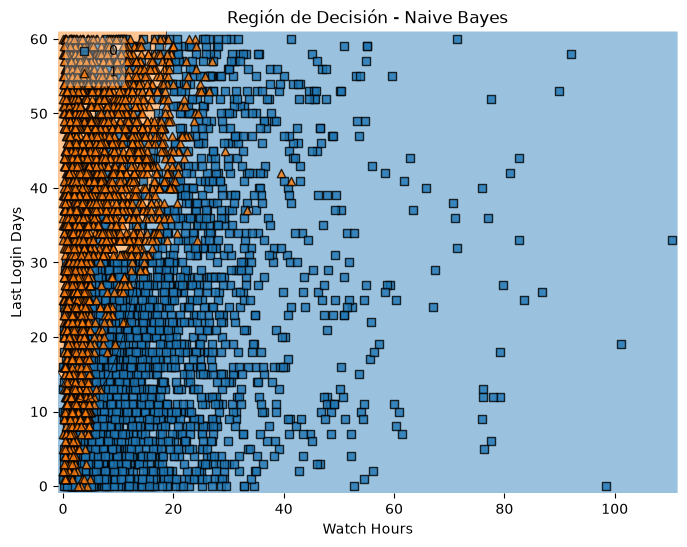

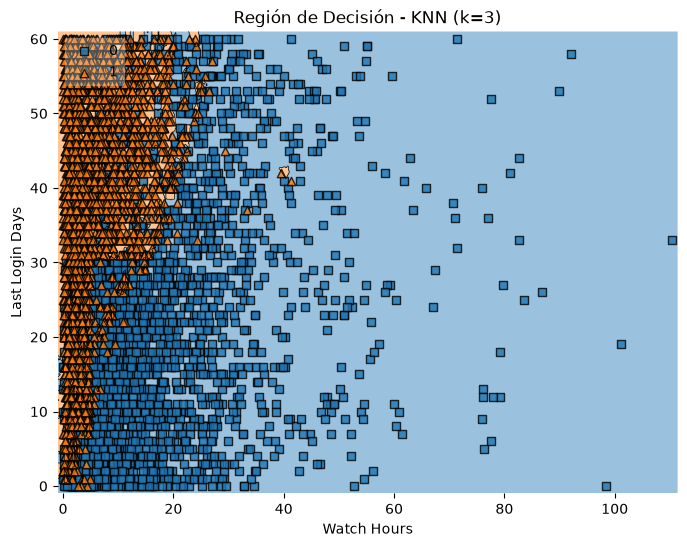

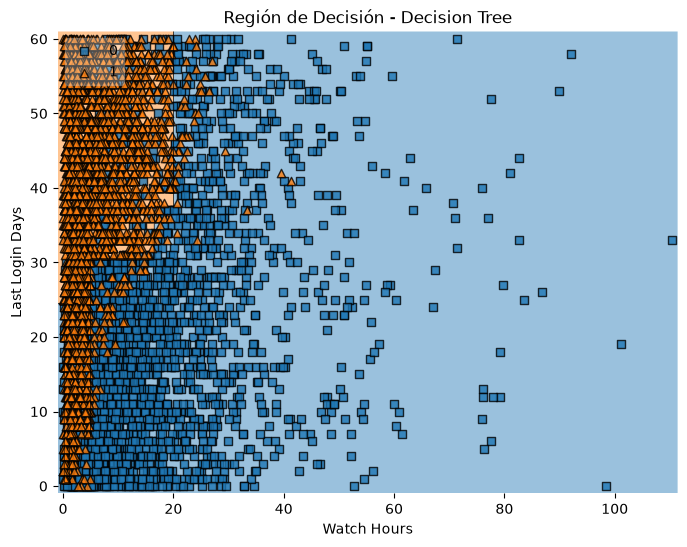

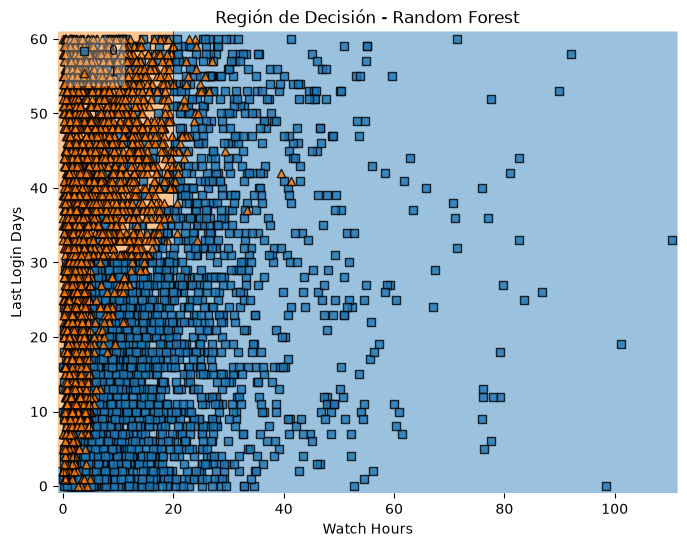

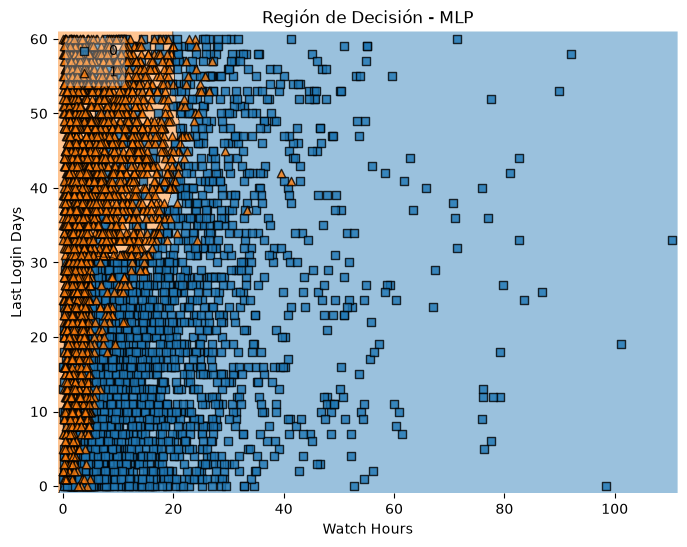

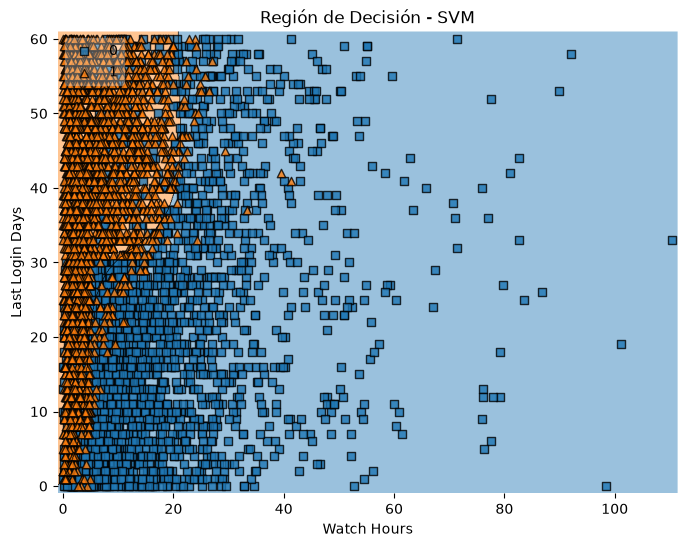

In [75]:
# Seleccionamos dos características para poder representarlas
# en un espacio bidimensional

X_plot = X[
    ["watch_hours", "last_login_days"]
].values

Y_plot = y.astype(int).values

# Entrenamos cada clasificador utilizando solamente estas dos variables
# para visualizar su frontera de decisión

for nombre, modelo in modelos_2d.items():

    modelo.fit(X_plot, Y_plot)

    plt.figure(figsize=(8, 6))

    plot_decision_regions(
        X_plot,
        Y_plot,
        clf=modelo,
        legend=2
    )

    plt.xlabel("Watch Hours")
    plt.ylabel("Last Login Days")

    plt.title(
        f"Región de Decisión - {nombre}"
    )

    plt.show()

In [76]:
# Estandarizamos todas las características
# antes de aplicar PCA

scaler_pca = StandardScaler()

X_scaled_pca = scaler_pca.fit_transform(X)

# PCA reduce todas nuestras características a dos dimensiones
# para poder visualizarlas

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled_pca)

print(
    "Varianza explicada:",
    pca.explained_variance_ratio_
)

print(
    "Varianza total:",
    pca.explained_variance_ratio_.sum()
)

Varianza explicada: [0.13225536 0.07937843]
Varianza total: 0.2116337908563479


In [77]:
# Creamos los modelos que serán entrenados
# sobre las dos componentes obtenidas mediante PCA

modelos_pca = {

    "Naive Bayes":
        GaussianNB(),

    f"KNN (k={mejor_k})":
        KNeighborsClassifier(n_neighbors=mejor_k),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=42
        ),

    "MLP":
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=1000,
            random_state=42
        ),

    "SVM":
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        )
}

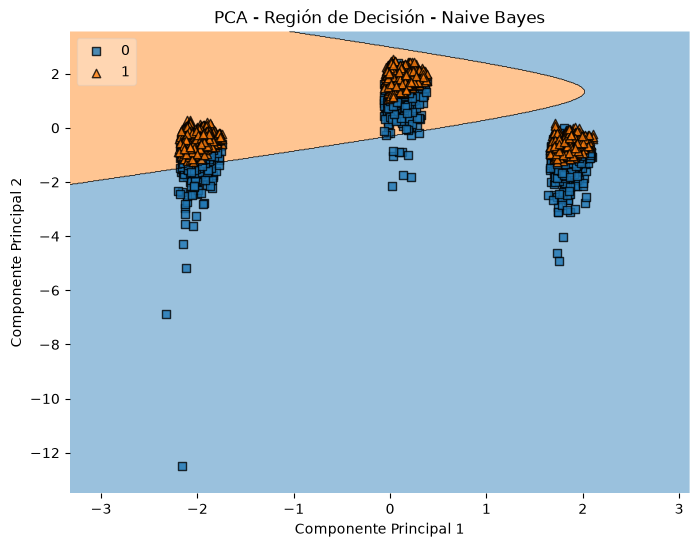

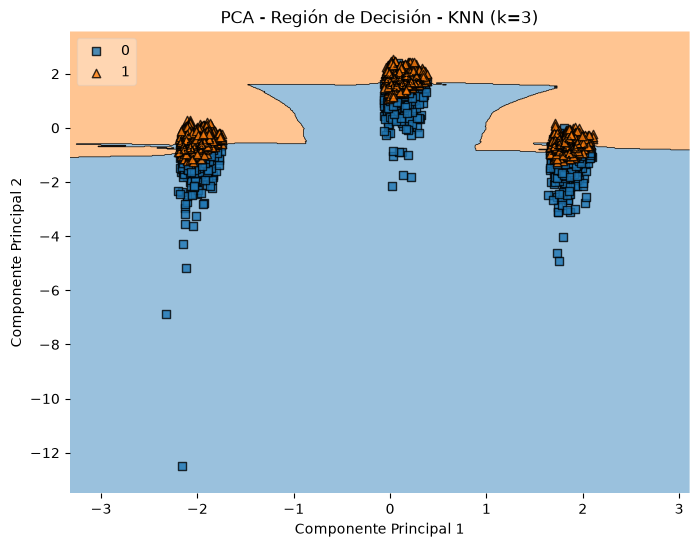

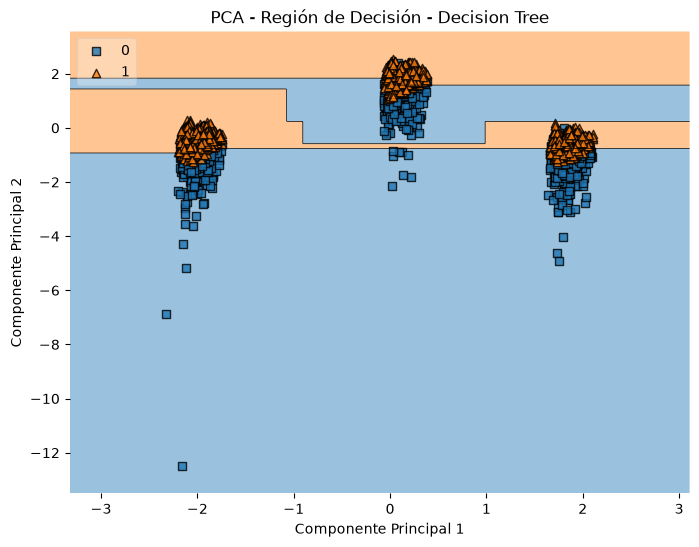

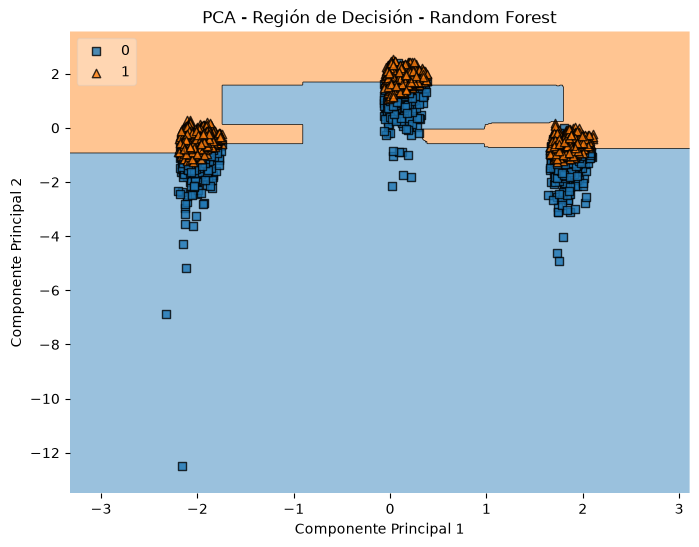

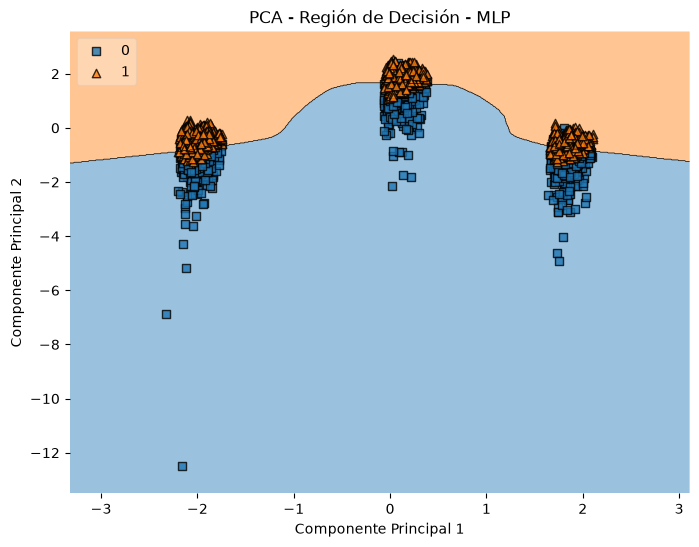

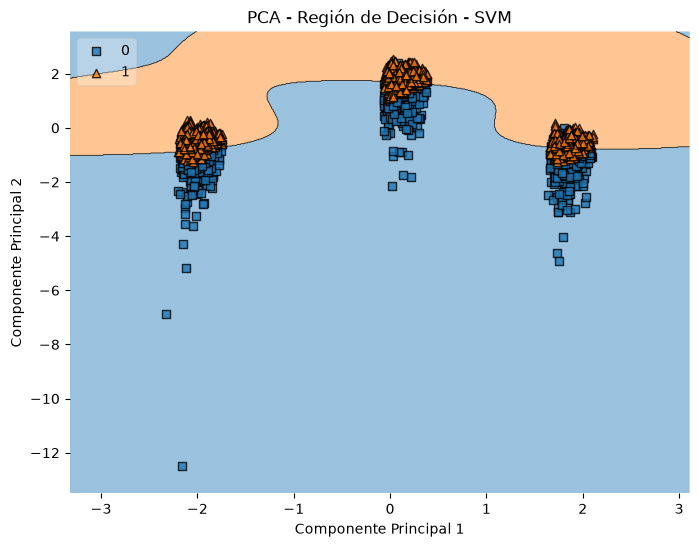

In [78]:
# Mostramos cómo cada clasificador separa Churn y No Churn
# utilizando las dos dimensiones generadas por PCA

Y_plot = y.astype(int).values

for nombre, modelo in modelos_pca.items():

    modelo.fit(X_pca, Y_plot)

    plt.figure(figsize=(8, 6))

    plot_decision_regions(
        X_pca,
        Y_plot,
        clf=modelo,
        legend=2
    )

    plt.xlabel("Componente Principal 1")
    plt.ylabel("Componente Principal 2")

    plt.title(
        f"PCA - Región de Decisión - {nombre}"
    )

    plt.show()

In [79]:
# Exportamos las métricas de los seis clasificadores
# para utilizarlas en el dashboard interactivo

resultados.to_csv(
    "resultados_modelos.csv",
    index=False
)

print("Resultados exportados correctamente")

Resultados exportados correctamente


In [80]:
# Exportamos los resultados de los clasificadores
# para utilizarlos en el dashboard de Streamlit

from pathlib import Path

ruta = Path.home() / "Netflix_clasificadores" / "resultados_modelos.csv"

resultados.to_csv(ruta, index=False)

print("Archivo guardado en:", ruta)
print("Total de modelos:", len(resultados))

Archivo guardado en: /Users/ricardovillarreal/Netflix_clasificadores/resultados_modelos.csv
Total de modelos: 6


In [81]:
# Exportamos los resultados y las visualizaciones
# para utilizarlos en el dashboard de Streamlit

from pathlib import Path
import sys

# Ubicación principal del proyecto
PROYECTO = Path.home() / "Netflix_clasificadores"

# Permitimos importar el exportador desde dashboard/
sys.path.insert(0, str(PROYECTO / "dashboard"))

from exportar_desde_notebook import exportar_dashboard

# Generamos los archivos para Streamlit
exportar_dashboard(
    globals(),
    carpeta=PROYECTO
)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.



✅ Exportación completada en: /Users/ricardovillarreal/Netflix_clasificadores
   - resultados_modelos.csv
   - evaluacion_modelos.csv
   - importancia_variables.csv
   - manifest_visualizaciones.csv
   - visualizaciones/ (árbol + regiones + PCA)
   - KNN seleccionado por validación cruzada: k=3

Coloca app.py, requirements.txt y netflix_customer_churn.csv en esta carpeta.


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Random Forest,0.951,0.926692,0.980119,0.952657,0.994744,0.995515
1,Decision Tree,0.926,0.940452,0.910537,0.925253,0.977473,0.972977
2,MLP,0.919,0.907336,0.934394,0.920666,0.981419,0.982129
3,SVM,0.914,0.908023,0.922465,0.915187,0.973187,0.974410
4,Naive Bayes,0.819,0.738872,0.990060,0.846219,0.949186,0.948829
5,KNN (k=3),0.829,0.809701,0.862823,0.835419,0.888540,0.845652
